# F08 — Inclination shallowing meets plate reconstruction: a corrected sedimentary paleolatitude on a reconstructed site


**Cluster F: Paleomagnetism.**
**Apply the King (1955) inclination-shallowing correction, with the flattening factor obtained by the SVEI method (Tauxe et al. 2024), to the published specimen-level directions of the Oligo-Miocene Xishuigou section (Gansu, China; Gilder et al. 2001), reconstruct the same site through Cao 2024 to the age of the rocks, and compare uncorrected paleolatitude, corrected paleolatitude and reconstructed paleolatitude in one four-bar figure.**

## What this notebook produces

For one sedimentary section we compute:

1. The **uncorrected paleolatitude** from the Fisher-mean inclination of the specimen directions (both polarities, reversed directions flipped), using the axial-dipole formula `tan(I) = 2·tan(λ)`.
2. The **shallowing-corrected paleolatitude** after unflattening with `tan(I_corr) = tan(I_obs) / f`. The flattening factor `f` is taken from an SVEI analysis of these same data (see below) and is varied over its published range to give an uncertainty band.
3. The **reconstruction-predicted paleolatitude** of the section at the age of the rocks in Cao 2024, with a band for the age range of the section.

The four bars are uncorrected, corrected, reconstructed, and the residual (corrected minus reconstructed), so that you can see whether ignoring shallowing biases the paleolatitude by more than the model–data residual.

**The data.** The Xishuigou section (Subei, Gansu Province) is about 2,180 m thick and was deposited between roughly 26 and 19 Ma (Gilder et al. 2001). The specimen-level directions are public in the MagIC database (contribution 20098, https://earthref.org/MagIC/20098). They are turned into the bundled CSV `data/paleomag/gilder2001_xishuigou_directions.csv` by the script `data/paleomag/build_gilder2001_csv.py`, which keeps the tilt-corrected specimen directions with MAD ≤ 10° (141 specimens, 77 of them with negative inclination, i.e. reversed polarity). MagIC stores the site position rounded to whole degrees (39°N, 95°E), which is adequate for a regional paleolatitude comparison.

**Where `f` comes from.** Inclination shallowing is commonly diagnosed and corrected with the elongation/inclination (E/I) method (Tauxe & Kent 2004). Tauxe et al. (2024) present an updated approach (SVEI) that is implemented in the `svei` module of PmagPy, whose demonstration notebook uses exactly the Gilder et al. (2001) data. There the best-fitting flattening factor is about 0.52, within a range of 0.40–0.65 for the quick version of the run. We use these values here as inputs rather than re-deriving them; to compute `f` yourself, run `svei.find_flat()` on the same directions.

**Audience**: postgrad.
**Difficulty**: ★★★.

## Learning objectives

- Apply the King (1955) inclination-shallowing correction with a given flattening factor `f` and see the resulting paleolatitude shift.
- Handle a real paleomagnetic data set: both polarities, flipping reversed directions to a common polarity, and the Fisher mean.
- Reconstruct a single site to its rock age with `gplately` and compare against the corrected paleomagnetic paleolatitude, including uncertainty bands from `f` and from the age range.
- Recognise where a full elongation-inclination (E/I or SVEI) analysis is needed to derive `f` — and which step in the notebook it would replace.

## Prerequisites and runtime

- Plate model: Cao 2024 default.
- Python: `gplately`, `pygmt`, `pygplates`, `numpy`, `pandas`.
- Bundled data: `data/paleomag/gilder2001_xishuigou_directions.csv` (build it once with `python data/paleomag/build_gilder2001_csv.py`; the script downloads the MagIC contribution).
- Runtime: a few seconds end-to-end.


In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from IPython.display import display, HTML
# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0.post19+git.2cce7bb3  pygmt v0.19.0  pygplates 1.0.0


## Configuration — change site + age + dataset here

In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME       = "Cao2024"
DATA_CSV         = "data/paleomag/gilder2001_xishuigou_directions.csv"
SITE_LON_LAT     = None           # None: mean of the site coordinates in the CSV (lon, lat)
ROCK_AGE_MA      = 22.5           # mid-point of the 26-19 Ma depositional age (Gilder et al. 2001)
AGE_RANGE_MA     = (19.0, 26.0)   # youngest and oldest age of the section
F_FLATTENING     = 0.52           # SVEI result for these data (PmagPy SVEI demonstration)
F_RANGE          = (0.40, 0.65)   # range of f that is compatible with the data in that run
# ============================================================================


## 1. Load the specimen directions

The CSV (one row per specimen: `dec`, `inc`, `mad`, site coordinates) is made from the MagIC contribution by `data/paleomag/build_gilder2001_csv.py`. The section contains normal and reversed polarity directions. Before averaging, reversed directions are replaced by their antipodes, using the principal axis of the data as reference.


In [3]:
# Cell 2 — load data
from pathlib import Path
if not Path(DATA_CSV).exists():
    raise FileNotFoundError(f"{DATA_CSV} not found. Build it once from the MagIC database with:\n"
                            "    python data/paleomag/build_gilder2001_csv.py")
sites = pd.read_csv(DATA_CSV, comment="#")


def flip_to_common_polarity(dec, inc):
    """Replace reversed directions by their antipodes (reference: principal axis of the data)."""
    d, i = np.deg2rad(dec), np.deg2rad(inc)
    xyz = np.column_stack([np.cos(i) * np.cos(d), np.cos(i) * np.sin(d), np.sin(i)])
    _, v = np.linalg.eigh(xyz.T @ xyz)
    axis = v[:, -1] if v[2, -1] >= 0 else -v[:, -1]
    xyz = xyz * np.where(xyz @ axis < 0, -1.0, 1.0)[:, None]
    return (np.degrees(np.arctan2(xyz[:, 1], xyz[:, 0])) % 360.0,
            np.degrees(np.arcsin(np.clip(xyz[:, 2], -1, 1))))


sites["dec_n"], sites["inc_n"] = flip_to_common_polarity(sites["dec"].values, sites["inc"].values)
n_rev = int((sites["inc"] < 0).sum())
if SITE_LON_LAT is None:
    SITE_LON_LAT = (float(sites["site_lon"].mean()), float(sites["site_lat"].mean()))
print(f"loaded {len(sites)} specimen directions ({n_rev} with negative inclination, flipped to common polarity)")
print(f"site: {SITE_LON_LAT[1]:.2f}°N, {SITE_LON_LAT[0]:.2f}°E")
sites.head()


loaded 141 specimen directions (77 with negative inclination, flipped to common polarity)
site: 39.00°N, 95.00°E


,specimen,sample,site,site_lat,site_lon,dec,inc,mad,dec_n,inc_n
0,6006,6006,6006,39,95.0,189.3,-64.4,3.2,9.3,64.4
1,6007,6007,6007,39,95.0,156.5,-37.2,4.8,336.5,37.2
2,6011,6011,6011,39,95.0,164.3,-29.5,7.4,344.3,29.5
3,6013,6013,6013,39,95.0,167.4,-34.7,8.4,347.4,34.7
4,6015,6015,6015,39,95.0,174.0,-9.2,8.8,354.0,9.2


## 2. King (1955) inclination-shallowing correction

We unflatten the Fisher-mean observed inclination via `tan(I_corr) = tan(I_obs) / f`, then convert to paleolatitude via the dipole formula. The flattening factor is the SVEI value for these data (`F_FLATTENING`); the range `F_RANGE` gives the uncertainty band. A smaller `f` means stronger flattening and therefore a larger correction.


In [4]:
# Cell 3 — King (1955) inclination-shallowing correction
#
#     tan(I_corr) = tan(I_obs) / f
#
# f in (0, 1] is the flattening factor. In a real study f comes from an
# elongation-inclination (E/I) analysis (Tauxe & Kent 2004) or from SVEI
# (Tauxe et al. 2024, PmagPy `svei.find_flat`) applied to the same directions.
# Here f is set in the configuration cell.

# Fisher-vector mean of the (polarity-normalised) directions
decs_r = np.deg2rad(sites["dec_n"].values)
incs_r = np.deg2rad(sites["inc_n"].values)
x_mean = np.mean(np.cos(incs_r) * np.cos(decs_r))
y_mean = np.mean(np.cos(incs_r) * np.sin(decs_r))
z_mean = np.mean(np.sin(incs_r))
R_mean = np.sqrt(x_mean**2 + y_mean**2 + z_mean**2)
inc_mean_obs = float(np.degrees(np.arcsin(z_mean / R_mean)))


def unflatten(inc_deg, f):
    return float(np.degrees(np.arctan(np.tan(np.deg2rad(inc_deg)) / f)))


def paleolat_from_inc(inc_deg):
    """Dipole formula  tan(I) = 2*tan(lat)."""
    return float(np.degrees(np.arctan(0.5 * np.tan(np.deg2rad(inc_deg)))))


f = F_FLATTENING
inc_c = unflatten(inc_mean_obs, f)
paleolat_uncorr = paleolat_from_inc(inc_mean_obs)
paleolat_corr   = paleolat_from_inc(inc_c)
# uncertainty band from the range of f (smaller f -> larger correction)
paleolat_corr_lo = paleolat_from_inc(unflatten(inc_mean_obs, F_RANGE[1]))
paleolat_corr_hi = paleolat_from_inc(unflatten(inc_mean_obs, F_RANGE[0]))

print(f"  observed mean inc:        {inc_mean_obs:+.1f}°")
print(f"  flattening factor f:      {f:.2f}  (range {F_RANGE[0]:.2f}-{F_RANGE[1]:.2f})")
print(f"  unflattened mean inc:     {inc_c:+.1f}°")
print(f"  paleolat uncorrected:     {paleolat_uncorr:+.1f}°N")
print(f"  paleolat corrected:       {paleolat_corr:+.1f}°N  (band {paleolat_corr_lo:+.1f} to {paleolat_corr_hi:+.1f}°N)")


  observed mean inc:        +44.5°
  flattening factor f:      0.52  (range 0.40-0.65)
  unflattened mean inc:     +62.1°
  paleolat uncorrected:     +26.1°N
  paleolat corrected:       +43.3°N  (band +37.0 to +50.8°N)


## 3. Reconstruct the site and read off predicted paleolatitude

The site is reconstructed to the mid-point age of the section, and to the youngest and oldest age to give an age band. The model's default (anchor 0) frame is used here; for a comparison with paleomagnetic latitudes the paleomagnetic frame is the appropriate one, so check which frame anchor 0 represents for the model you use (see A02).


In [5]:
# Cell 4 — reconstruct
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
)
pt = gplately.Points(recon, [SITE_LON_LAT[0]], [SITE_LON_LAT[1]])


def paleolat_at(age_ma):
    rlons, rlats = pt.reconstruct(age_ma, return_array=True)   # lons first!
    return float(rlats[0])


paleolat_recon = paleolat_at(ROCK_AGE_MA)
_band = [paleolat_at(a) for a in AGE_RANGE_MA]
paleolat_recon_lo, paleolat_recon_hi = min(_band), max(_band)
print(f"  reconstructed paleolat: {paleolat_recon:+.1f}°  (model={MODEL_NAME}, t={ROCK_AGE_MA:.1f} Ma; "
      f"{AGE_RANGE_MA[0]:.0f}-{AGE_RANGE_MA[1]:.0f} Ma: {paleolat_recon_lo:+.1f} to {paleolat_recon_hi:+.1f}°)")


  reconstructed paleolat: +41.3°  (model=Cao2024, t=22.5 Ma; 19-26 Ma: +41.0 to +41.4°)


## 4. Four-bar comparison

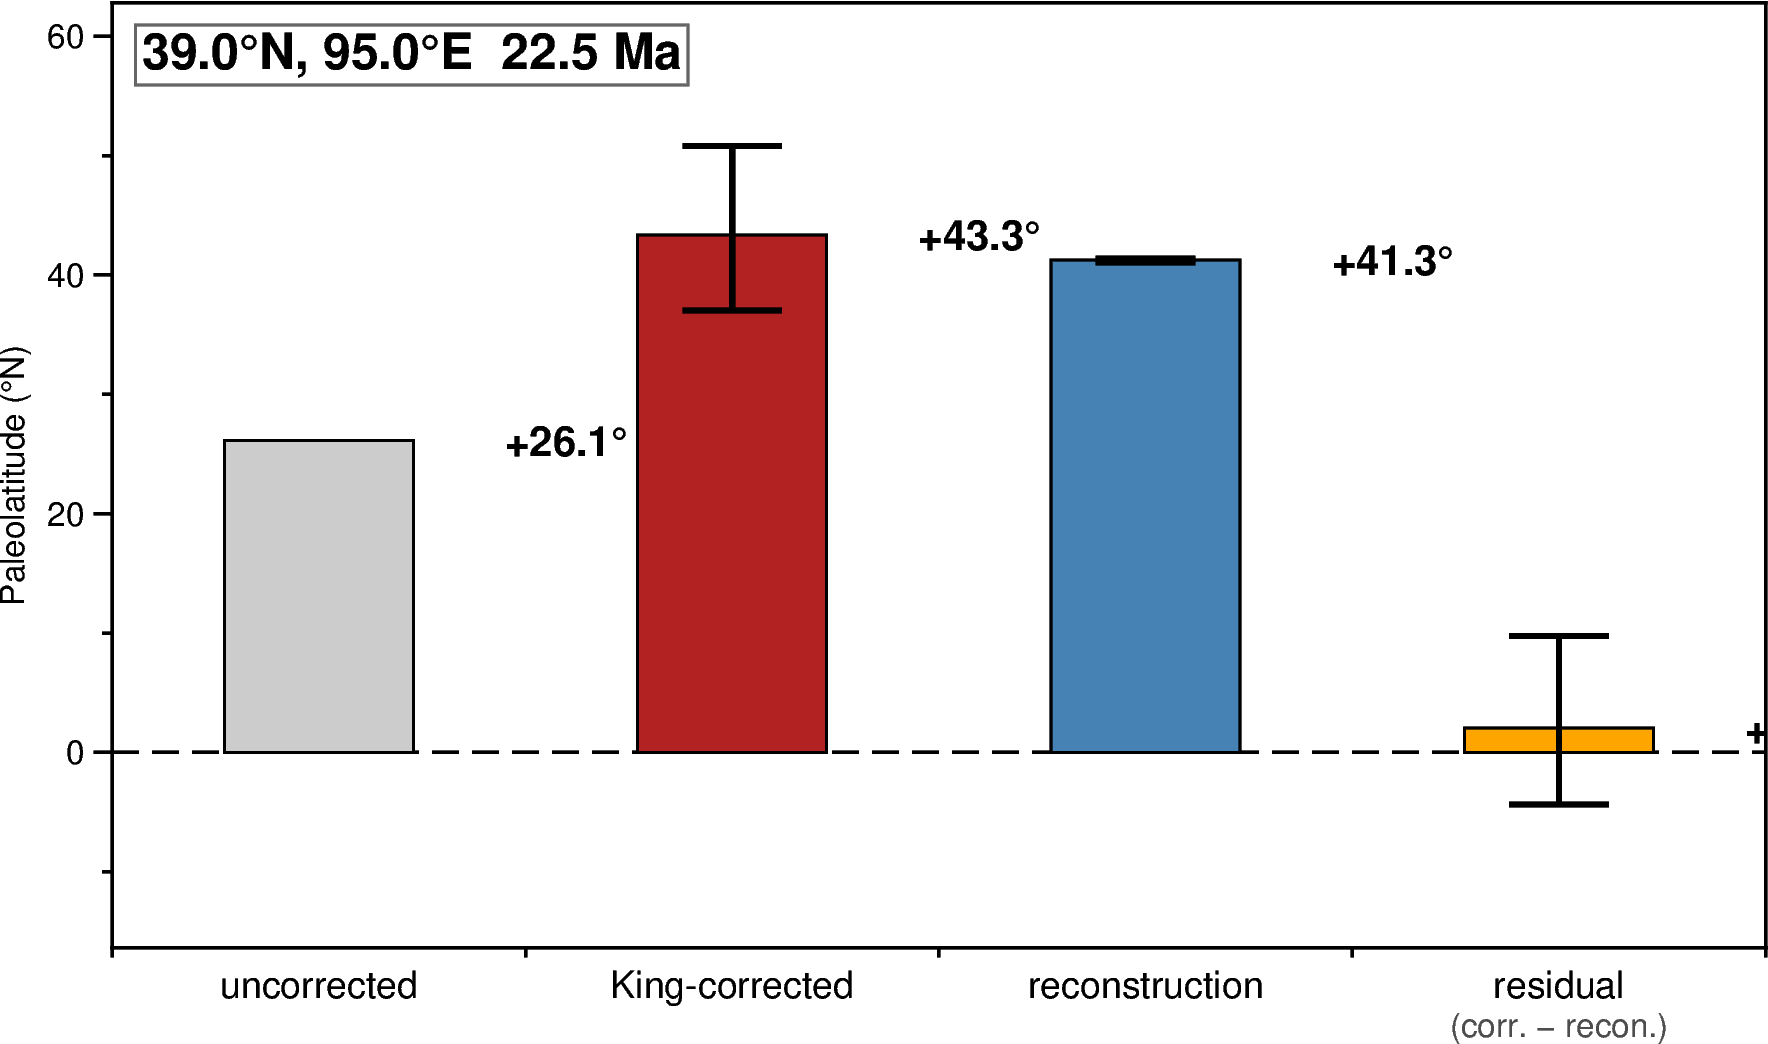

In [6]:
# Cell 5 — bar comparison (values can be negative: baseline at 0°)
labels = ["uncorrected", "King-corrected", "reconstruction", "residual\n(corr. − recon.)"]
values = [paleolat_uncorr, paleolat_corr, paleolat_recon, paleolat_corr - paleolat_recon]
fills  = ["gray80", "firebrick", "steelblue", "orange"]      # light/mid fills: labels stay readable
# uncertainty bands: f range for the corrected bar, age range for the reconstruction,
# both for the residual
bands = [None,
         (paleolat_corr_lo, paleolat_corr_hi),
         (paleolat_recon_lo, paleolat_recon_hi),
         (paleolat_corr_lo - paleolat_recon_hi, paleolat_corr_hi - paleolat_recon_lo)]

lo_all = min([0] + values + [b[0] for b in bands if b])
hi_all = max([0] + values + [b[1] for b in bands if b])
ymin, ymax = lo_all - 12, hi_all + 12
fig = pygmt.Figure()
fig.basemap(region=[0, 4, ymin, ymax], projection="X14c/8c",
            frame=["xf1", "yaf+lPaleolatitude (°N)", "WSrt"])
fig.plot(x=[0, 4], y=[0, 0], pen="0.8p,black,--")           # equator reference
for i, (lab, val, col, bnd) in enumerate(zip(labels, values, fills, bands)):
    xc = i + 0.5
    fig.plot(x=[xc], y=[val], style="b1.6c+b0", fill=col, pen="0.6p,black")
    top = val
    if bnd:
        fig.plot(x=[xc, xc], y=[bnd[0], bnd[1]], pen="1.4p,black")
        for yb in bnd:
            fig.plot(x=[xc - 0.12, xc + 0.12], y=[yb, yb], pen="1.4p,black")
        top = bnd[1] if val >= 0 else bnd[0]
    # value label beyond the bar end (and its band) so it never sits on the fill
    fig.text(x=[xc + 0.45], y=[val], text=f"{val:+.1f}°", font="10p,Helvetica-Bold,black",
             justify="ML")
    fig.text(x=[xc], y=[ymin], text=lab.split("\n")[0], font="9p,Helvetica,black",
             justify="TC", offset="0/-0.2c", no_clip=True)
    if "\n" in lab:
        fig.text(x=[xc], y=[ymin], text=lab.split("\n")[1], font="8p,Helvetica,gray30",
                 justify="TC", offset="0/-0.55c", no_clip=True)

fig.text(text=f"{SITE_LON_LAT[1]:.1f}°N, {SITE_LON_LAT[0]:.1f}°E @ {ROCK_AGE_MA:.1f} Ma",
         position="TL", offset="0.25c/-0.25c", justify="TL",
         font="12p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")
fig.show(width=900)
display(HTML('<div style="height:1cm"></div>'))


## What the figure shows

Four paleolatitudes for the Xishuigou section at about 22.5 Ma. The dashed zero line is the paleo-equator, so bars can point up (northern hemisphere) or down (negative values, in particular a residual). Whiskers show the uncertainty bands:

- **uncorrected (light gray)**: paleolatitude implied by the raw Fisher-mean inclination, before any shallowing correction.
- **King-corrected (red)**: paleolatitude after `tan(I_corr) = tan(I_obs) / f` with the SVEI value of `f`; the whisker spans the range of `f` in `F_RANGE`. Because a smaller `f` corrects more, the upper whisker end belongs to `f = F_RANGE[0]`.
- **reconstruction (blue)**: paleolatitude predicted by `gplately.Points.reconstruct()` at the mid-point age in Cao 2024; the whisker spans the youngest to the oldest age of the section.
- **residual (orange)**: `corrected − reconstruction`. It is negative when the model puts the site farther north than the corrected data do. The whisker combines both bands.

How to read it: the distance between the gray and red bars is the bias that the shallowing correction removes; the red and blue bars are then compared within their whiskers. When the corrected and reconstructed paleolatitudes agree within the bands, shallowing is a sufficient explanation of the difference between the raw data and the model. A residual that stays outside the bands points to the correction (a different `f`), to a tectonic effect that a dipole-latitude comparison cannot resolve (for example vertical-axis rotation, which changes declination, not latitude), to the frame used for the reconstruction, or to the model at this age and place. For the Xishuigou directions the polarity-normalised mean inclination is about 44.5°, which corresponds to an uncorrected paleolatitude of about 26°N. With `f = 0.52` the inclination becomes about 62° (paleolatitude about 43°N); the range `f` = 0.65–0.40 spans about 37–51°N. These values are printed by cell 3.

Cao 2024 places the site at about 41.3°N at 22.5 Ma (41.0–41.4°N across 26–19 Ma; printed by cell 4). The corrected paleolatitude (43.3°N) exceeds it by only about 2°, and the model value lies inside the band of the corrected value (37–51°N). The uncorrected paleolatitude (26.1°N) is about 15° too low. In this example the inclination-shallowing correction therefore brings the paleomagnetic data into agreement with the plate model, while the raw data would have suggested a large discrepancy.


## Extend this

- **Swap plate models.** Re-run with `MODEL_NAME = "Zahirovic2022"` or `"Merdith2021"`. The reconstruction-predicted paleolatitude depends on which model you trust; if the SVEI-corrected paleolatitude lies between two models, you have a discriminator.
- **Sweep the rock age.** The section spans several million years. Sweep `ROCK_AGE_MA` across the interval and plot how the reconstruction-predicted paleolatitude evolves.
- **Different dataset.** SVEI and the King correction work on any sedimentary collection. Build a CSV with columns `dec`, `inc` and the site coordinates from another study in the MagIC database and set `DATA_CSV`, `ROCK_AGE_MA` and `F_FLATTENING` accordingly.
- **Derive `f` yourself.** Run `svei.find_flat()` from PmagPy on the polarity-normalised directions and compare its `f` with the value used here.
- **Cross-reference F06.** The Osler case in F06 is the *rigid-block* analogue of this notebook — paleomagnetic pole versus reconstruction prediction. F08 is the sedimentary, inclination-only version of the same test.

## References

- MagIC database, contribution 20098 (specimen-level data of Gilder et al. 2001): https://earthref.org/MagIC/20098
- Tauxe, L., Heslop, D. & Gilder, S.A. (2024). Assessing paleosecular variation averaging and correcting paleomagnetic inclination shallowing. *Journal of Geophysical Research: Solid Earth* 129(8), e2024JB029502. https://doi.org/10.1029/2024JB029502
- Tauxe, L. & Kent, D.V. (2004). A simplified statistical model for the geomagnetic field and the detection of shallow bias in paleomagnetic inclinations: was the ancient magnetic field dipolar? In: *Timescales of the Paleomagnetic Field*, AGU Geophysical Monograph 145, 101–115. https://doi.org/10.1029/145GM08
- Gilder, S., Chen, Y. & Sen, S. (2001). Oligo-Miocene magnetostratigraphy and rock magnetism of the Xishuigou section, Subei (Gansu Province, western China) and implications for shallow inclinations in central Asia. *J. Geophys. Res.* 106(B12), 30505–30521. https://doi.org/10.1029/2001JB000325
- King, R.F. (1955). The remanent magnetism of artificially deposited sediments. *Mon. Not. R. Astron. Soc., Geophys. Suppl.* 7(3), 115–134. https://doi.org/10.1111/j.1365-246X.1955.tb06558.x
- Cao, X., Collins, A.S., Pisarevsky, S., Flament, N., Li, S., Hasterok, D. & Müller, R.D. (2024). Earth's tectonic and plate boundary evolution over 1.8 billion years. *Geoscience Frontiers* 15, 101922. https://doi.org/10.1016/j.gsf.2024.101922
- Mather, B.R. et al. (2024). *Geoscience Data Journal* 11, 3–10.
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Tong, J.-H., Ngo, L., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J. & Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515
